In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("train.csv")

print(df.head())
print(df.shape)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

In [2]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [3]:
# Fill missing Age values
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing Embarked values
df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0]
)

print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [4]:
# Survival Analysis

print("Survival Count:")
print(df["Survived"].value_counts())

total_passengers = len(df)
survived = df["Survived"].sum()
not_survived = total_passengers - survived

survival_rate = (survived / total_passengers) * 100

print("\nTotal Passengers:", total_passengers)
print("Survived:", survived)
print("Not Survived:", not_survived)
print("Survival Rate:", round(survival_rate, 2), "%")

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Total Passengers: 891
Survived: 342
Not Survived: 549
Survival Rate: 38.38 %


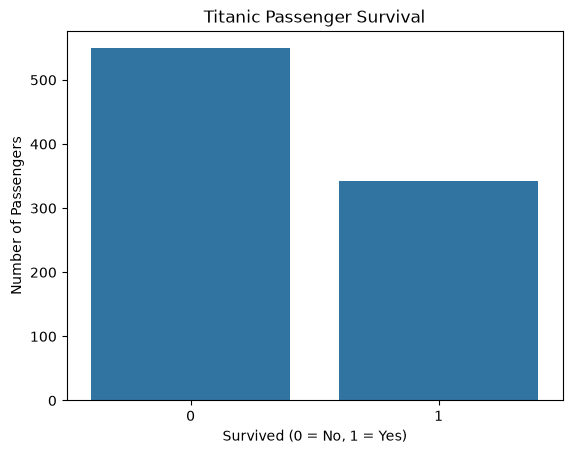

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Survived")

plt.title("Titanic Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

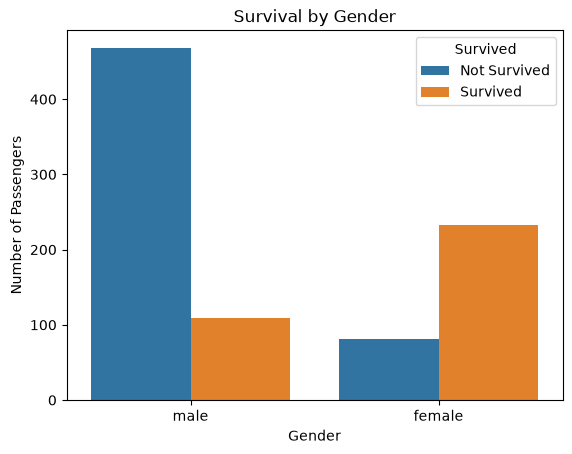

In [6]:
sns.countplot(data=df, x="Sex", hue="Survived")

plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["Not Survived", "Survived"])

plt.show()

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


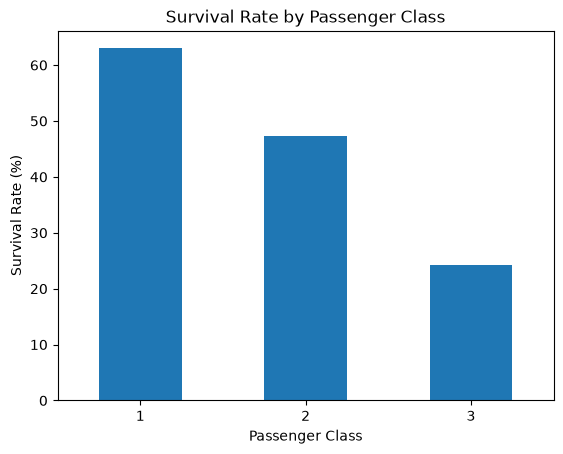

In [7]:
# Survival Rate by Passenger Class

class_rate = df.groupby("Pclass")["Survived"].mean() * 100

print(class_rate)

class_rate.plot(kind="bar")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)

plt.show()

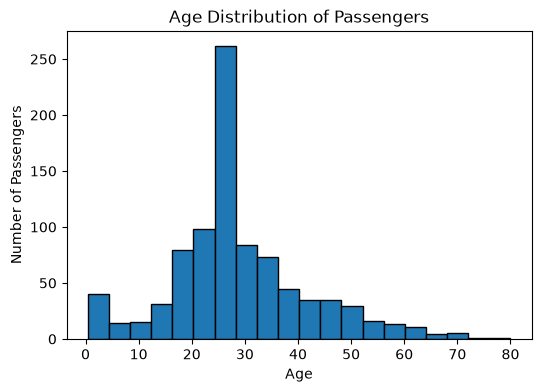

In [8]:
# Age Distribution Histogram

plt.figure(figsize=(6, 4))

plt.hist(df["Age"], bins=20, edgecolor="black")

plt.title("Age Distribution of Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

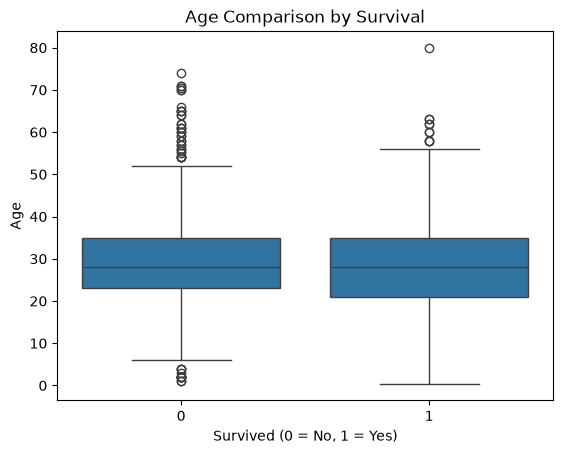

In [9]:
# Age Comparison by Survival

sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Age Comparison by Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()

In [10]:
print("--- Titanic Project Conclusion ---")

print("Total Passengers:", len(df))

print(
    "Survival Rate:",
    round(df["Survived"].mean() * 100, 2),
    "%"
)

gender_rate = df.groupby("Sex")["Survived"].mean() * 100
class_rate = df.groupby("Pclass")["Survived"].mean() * 100

print("\nSurvival Rate by Gender:")
print(gender_rate)

print("\nSurvival Rate by Passenger Class:")
print(class_rate)

print("\nProject Completed Successfully!")

--- Titanic Project Conclusion ---
Total Passengers: 891
Survival Rate: 38.38 %

Survival Rate by Gender:
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

Project Completed Successfully!
